# Домашнее задание №2 · Обучение без учителя

## Выполнил Евтушенко И. А., студент группы Б05-320

МФТИ · «Практическое машинное обучение» · максимум 100 баллов.

**Дедлайн: 6 ноября 2026 года, 23:59 МСК.** При опоздании итоговый балл умножается на коэффициент:

| Опоздание | Коэффициент |
|---|---:|
| 1 день | 0,75 |
| 2 дня | 0,50 |
| 3 дня | 0,25 |

Ориентир по времени работы — 8–10 часов.

## Что нужно сделать

Исследуйте данные, найдите кластеры и проверьте, как они меняются при преобразовании признаков, сжатии данных и повторном обучении. Объясните различия между кластерами и оцените устойчивость результата.

**Свой вариант посмотрите на Stepik.** Выполняйте только свой вариант.

| Вариант | Данные | Что исследовать |
|---|---|---|
| A · Яндекс Музыка | 5000 пользователей, 8 признаков | Режимы активности и постановки лайков |
| B · Радиосигналы | 5000 кандидатов, 8 признаков | Типы сигналов и необычные наблюдения |
| C · Датчики смартфона | 5000 окон наблюдений, 12 признаков | Режимы движения |
| D · Велопрокат | 352 дня, 24 почасовых значения | Объём аренд и распределение спроса в течение дня |

Все данные находятся в `02_Данные.zip`. Достаточно обычного компьютера или Colab; описание признаков — в конце ноутбука. Готова только загрузка данных. Остальной код напишите самостоятельно; можно использовать материалы занятий.

## Как использовать данные

Вы описываете выданный набор целиком, поэтому для этой работы разделять его на train/test не нужно. Перенос результата на новых пользователей или будущие периоды потребует отдельной проверки.

`object_id` — ID строки, `group_id` — служебная метка для повторной выборки в задании 5. Не включайте их в признаки. Остальные поля из файлов `*_metadata.csv` открывайте только в задании 7, после выбора модели. Не используйте известные классы для подбора числа кластеров, признаков или параметров.

## Загрузка данных

Положите `02_Данные.zip` рядом с ноутбуком; в Colab загрузите его через панель файлов. Укажите свой вариант в строке `VARIANT`. Ячейка загрузит таблицу признаков `data` и служебные метки `groups` для задания 5.

[Скачать данные](https://drive.google.com/file/d/1CG0kt6bm4E1oEJuxdr3HpVEx-4IHhv9Z/view) · [Папка задания](https://drive.google.com/drive/folders/12d4DMQYQbctGG73a0OXTbdAhOXMkb5He)

In [1]:
from pathlib import Path
from zipfile import ZipFile
import time
import pandas as pd

T_START = time.perf_counter()
VARIANT = "C"  # укажите свой вариант из Stepik: A, B, C или D
DATA_FILE = Path("02_Данные.zip")

with ZipFile(DATA_FILE) as archive:
    def member(kind):
        # В выданном архиве файлы лежат внутри папки 02_Данные/, поэтому ищем их по окончанию пути
        return next(name for name in archive.namelist() if name.endswith(f"data/{VARIANT}_{kind}.csv"))
    data = pd.read_csv(archive.open(member("features")), index_col="object_id")
    groups = pd.read_csv(archive.open(member("metadata")),
                         usecols=["object_id", "group_id"], dtype=str).set_index("object_id")
data.index = data.index.astype(str)
groups = groups.loc[data.index, "group_id"]
print("Данные:", data.shape)

Данные: (5000, 12)


## 1. Данные и подготовка признаков · 15 баллов

1. Опишите, что означает одна строка данных и для чего могут пригодиться найденные кластеры. До расчётов запишите две гипотезы: о возможных кластерах и о влиянии преобразования признаков.
2. Проверьте типы, пропуски, постоянные столбцы, одинаковые строки и распределения признаков. Покажите хотя бы один график и поясните его. Одинаковые измерения не удаляйте без обоснования.
3. Подготовьте два набора признаков: базовый и изменённый.

**Базовый:** все выданные признаки после `StandardScaler`.

**Изменённый — по вашему варианту:**

| Вариант | Преобразование |
|---|---|
| A | Примените `log1p` к `like_count`, `unique_tracks`, `active_days`, `span_days`, `likes_per_active_day`, `median_gap_hours`. Затем примените `StandardScaler` ко всем 8 признакам. Доли не логарифмируйте. |
| B | Примените `RobustScaler` ко всем 8 признакам. Используйте медиану и межквартильный размах. |
| C | Оставьте 6 признаков со `std()` в названии и примените `StandardScaler`. |
| D | Разделите 24 почасовых числа каждого дня на общее число аренд за этот день. Затем примените `StandardScaler` к полученным столбцам. |

Объясните, какие различия между объектами после преобразования влияют на расстояния сильнее или слабее. Для D сравниваются число аренд и их доли по часам.

**Что означает строка.** Одна строка - окно измерений длительностью 2.56 с от акселерометра и гироскопа смартфона на поясе участника: средние и стандартные отклонения ускорения тела и угловой скорости по трём осям. Кластеры могут пригодиться, чтобы без ручной разметки выделить режимы движения: отфильтровать окна покоя, подготовить группы окон для разметки экспертом, считать время активности человека.

**Гипотезы, записанные до расчётов.**

1. О кластерах: окна разделятся как минимум на две группы - покой (сидение, стояние, лёжа) с почти нулевым разбросом сигналов и движение (ходьба, лестница) с большим разбросом. Внутри движения возможно деление по интенсивности.
2. О преобразовании: признаки `mean()` по окну мало меняются между режимами и близки к шуму, а `std()` прямо отражают интенсивность движения. Если оставить только 6 признаков `std()`, разделение покоя и движения станет чётче, силуэт на своих признаках вырастет, но различия, которые есть только в средних, пропадут.

типы: {'float64': 12}
пропусков: 0 | постоянных столбцов: 0 | одинаковых строк: 0 | повторов object_id: 0
значения от -1.000 до 1.000; участников (group_id): 30, окон на участника от 129 до 223


,mean,std,min,median,max
tBodyAcc-mean()-X,0.275,0.069,-0.854,0.277,1.000
tBodyAcc-mean()-Y,-0.018,0.034,-1.000,-0.017,0.536
tBodyAcc-mean()-Z,-0.109,0.054,-1.000,-0.109,1.000
tBodyAcc-std()-X,-0.614,0.436,-1.000,-0.947,1.000
tBodyAcc-std()-Y,-0.518,0.497,-1.000,-0.847,0.980
tBodyAcc-std()-Z,-0.616,0.405,-1.000,-0.865,1.000
tBodyGyro-mean()-X,-0.029,0.180,-0.773,-0.028,0.767
tBodyGyro-mean()-Y,-0.077,0.135,-1.000,-0.075,0.708
tBodyGyro-mean()-Z,0.089,0.137,-1.000,0.086,0.941
tBodyGyro-std()-X,-0.726,0.297,-1.000,-0.906,0.887


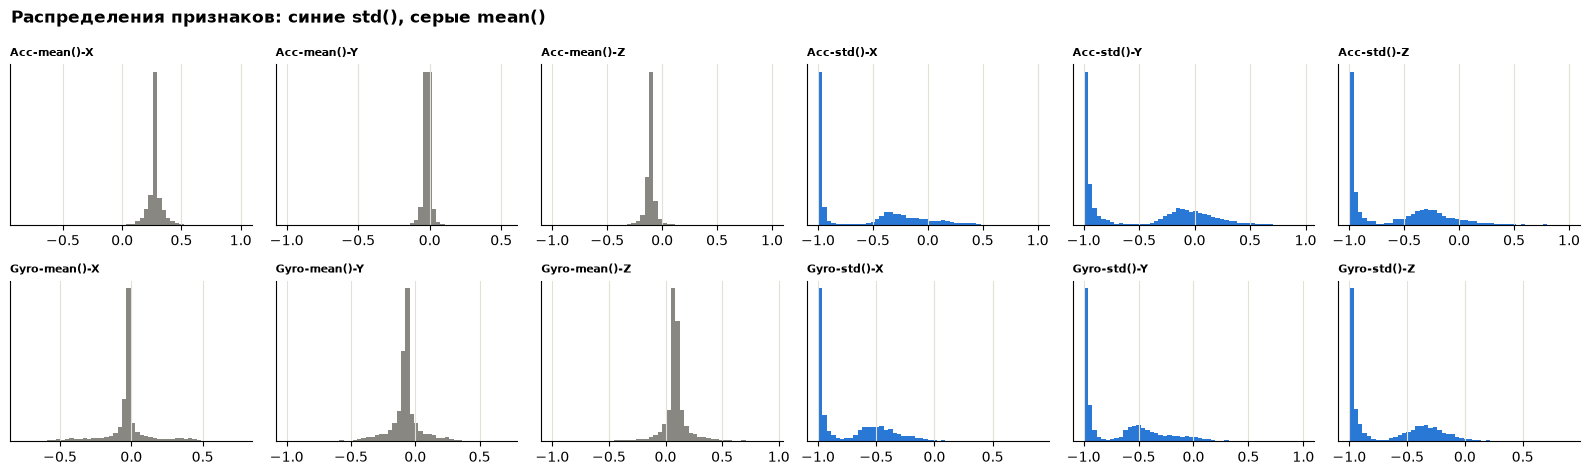

доля окон с std() меньше -0.9: {'Acc-std()-X': 0.529, 'Acc-std()-Y': 0.466, 'Acc-std()-Z': 0.478, 'Gyro-std()-X': 0.504, 'Gyro-std()-Y': 0.513, 'Gyro-std()-Z': 0.493}
базовый набор: (5000, 12) | изменённый набор: (5000, 6)


In [2]:
# 1. Аудит данных и два набора признаков
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler

SEED = 42
COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
mpl.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e1e0d9',
                     'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'legend.frameon': False})


def note(text):
    """Вывод через Markdown, чтобы работал LaTeX."""
    display(Markdown(text))


STD_COLS = [c for c in data.columns if 'std()' in c]
print('типы:', data.dtypes.astype(str).value_counts().to_dict())
print('пропусков:', int(data.isna().sum().sum()), '| постоянных столбцов:', int((data.nunique() <= 1).sum()),
      '| одинаковых строк:', int(data.duplicated().sum()), '| повторов object_id:', int(data.index.duplicated().sum()))
print(f'значения от {data.min().min():.3f} до {data.max().max():.3f}; '
      f'участников (group_id): {groups.nunique()}, окон на участника от {groups.value_counts().min()} до {groups.value_counts().max()}')
display(data.agg(['mean', 'std', 'min', 'median', 'max']).T.round(3))

fig, axes = plt.subplots(2, 6, figsize=(16, 4.8))
for ax, col in zip(axes.flat, data.columns):
    ax.hist(data[col], bins=50, color=COLORS[0] if col in STD_COLS else '#898781')
    ax.set_title(col.replace('tBody', ''), fontsize=8)
    ax.set_yticks([])
fig.suptitle('Распределения признаков: синие std(), серые mean()', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()
print('доля окон с std() меньше -0.9:',
      {c.replace('tBody', ''): round(float((data[c] < -0.9).mean()), 3) for c in STD_COLS})

# Два набора признаков: базовый (все 12) и изменённый (6 признаков std())
scaler_base = StandardScaler().fit(data)
scaler_mod = StandardScaler().fit(data[STD_COLS])
X_base = scaler_base.transform(data)
X_mod = scaler_mod.transform(data[STD_COLS])
FEATURE_SETS = {'base': X_base, 'mod': X_mod}
print('базовый набор:', X_base.shape, '| изменённый набор:', X_mod.shape)

**Аудит.** Все 12 столбцов типа float64. Пропусков 0, постоянных столбцов 0, одинаковых строк 0, повторов `object_id` 0, поэтому удалять нечего. Значения лежат от -1.000 до 1.000: это нормировка источника, а не физические единицы. В данных 30 участников, у каждого от 129 до 223 окон.

**График распределений.** Признаки `mean()` (серые) образуют узкий пик: например, у `tBodyAcc-mean()-X` медиана 0.277 при стандартном отклонении 0.069. Из ускорения тела гравитация уже вычтена, поэтому среднее по окну мало зависит от режима. Признаки `std()` (синие) двугорбые: высокий пик у -1 и широкий горб правее. Доля окон с `std()` меньше -0.9 по шести признакам от 0.466 до 0.529, то есть около половины окон почти без колебаний. Это поддерживает гипотезу 1 о группах покоя и движения. Хвосты у `mean()` могут быть резкими движениями.

**Два набора признаков.** В обоих наборах признак стандартизуется как $z_j = (x_j - \mu_j) / \sigma_j$, а k-means использует расстояние $d(x, y)^2 = \sum_j (z_j(x) - z_j(y))^2$.

- Базовый набор, 12 признаков. Стандартизация даёт каждому признаку единичную дисперсию, поэтому мелкие колебания почти постоянных `mean()` (у `tBodyAcc-mean()-Y` стандартное отклонение 0.034) получают тот же вес, что и разница покоя и движения в `std()`. Половина слагаемых расстояния описывает среднее ускорение и среднее вращение внутри окна.
- Изменённый набор, 6 признаков `std()`. Расстояние определяется только интенсивностью колебаний ускорения и угловой скорости. Различия в средних, например поворот корпуса за время окна, на расстояние больше не влияют, а вес интенсивности в сумме растёт.

## 2. Реализация k-means · 15 баллов

Реализуйте k-means на NumPy и проверьте его на небольшом синтетическом примере. Нужны назначение ближайшего центра, обновление центров и расчёт суммы квадратов расстояний до них (`inertia`). При равных расстояниях выбирайте центр с меньшим индексом; пустому кластеру сохраняйте прежний центр.

Покажите, что обновление центров при фиксированных назначенных кластерах не увеличивает `inertia`. Останавливайте цикл, когда центры перестают меняться, но не позднее 100 итераций. Сверьте центры и `inertia` со sklearn при тех же стартовых центрах, `n_init=1` и строгом допуске `tol`, учитывая возможную перестановку номеров кластеров. В следующих заданиях используйте sklearn.

In [3]:
# 2. k-means на NumPy
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score


def assign(X, centers):
    """Номер ближайшего центра; argmin при равных расстояниях берёт меньший индекс."""
    d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    return d2.argmin(axis=1)


def update_centers(X, labels, centers):
    """Среднее точек кластера; пустой кластер сохраняет прежний центр."""
    new = centers.copy()
    for k in range(len(centers)):
        if (labels == k).any():
            new[k] = X[labels == k].mean(axis=0)
    return new


def inertia(X, labels, centers):
    return float(((X - centers[labels]) ** 2).sum())


def kmeans_numpy(X, init_centers, max_iter=100):
    """Lloyd: назначение, обновление центров; стоп, когда центры не меняются, но не позже max_iter."""
    centers, steps = np.asarray(init_centers, dtype=float).copy(), []
    for iteration in range(1, max_iter + 1):
        labels = assign(X, centers)
        new = update_centers(X, labels, centers)
        steps.append((inertia(X, labels, centers), inertia(X, labels, new)))   # до и после обновления
        if np.array_equal(new, centers):
            break
        centers = new
    labels = assign(X, centers)
    return centers, labels, inertia(X, labels, centers), iteration, steps


# Проверки правил на маленьких примерах
print('равные расстояния: точка 0 между центрами -1 и 1 ->', assign(np.array([[0.0]]), np.array([[-1.0], [1.0]]))[0])
X_toy = np.array([[0.0, 0.0], [0.0, 1.0], [5.0, 5.0], [5.0, 6.0]])
c_toy, l_toy, _, _, _ = kmeans_numpy(X_toy, [[0.0, 0.5], [5.0, 5.5], [100.0, 100.0]])
print('пустой кластер: размеры', np.bincount(l_toy, minlength=3).tolist(), '| центр 2 остался', c_toy[2].tolist())

# Синтетический пример и сверка со sklearn при тех же стартовых центрах
X_syn, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=0)
init = X_syn[:3]
centers, labels, J, n_iter, steps = kmeans_numpy(X_syn, init)
growth = max(after - before for before, after in steps)
sk = KMeans(n_clusters=3, init=init, n_init=1, max_iter=100, tol=0.0, algorithm='lloyd').fit(X_syn)
rows, cols = linear_sum_assignment(((centers[:, None] - sk.cluster_centers_[None]) ** 2).sum(axis=2))
print(f'итераций: {n_iter}; ARI меток со sklearn: {adjusted_rand_score(labels, sk.labels_):.3f}')
note(rf'Обновление центров не увеличивает inertia: $\max(J_{{\text{{после}}}} - J_{{\text{{до}}}}) = {growth:.2g}$ по {len(steps)} шагам. '
     rf'Сверка со sklearn: $\max|c - c_{{sk}}| = {np.abs(centers[rows] - sk.cluster_centers_[cols]).max():.1e}$, '
     rf'$J = {J:.6f}$, $J_{{sk}} = {sk.inertia_:.6f}$.')

равные расстояния: точка 0 между центрами -1 и 1 -> 0
пустой кластер: размеры [2, 2, 0] | центр 2 остался [100.0, 100.0]
итераций: 7; ARI меток со sklearn: 1.000


Обновление центров не увеличивает inertia: $\max(J_{\text{после}} - J_{\text{до}}) = 0$ по 7 шагам. Сверка со sklearn: $\max|c - c_{sk}| = 1.3e-15$, $J = 536.367942$, $J_{sk} = 536.367942$.

- **Назначение.** Считаю квадраты расстояний до всех центров. `argmin` возвращает первый минимум, то есть центр с меньшим индексом: точка 0 между центрами -1 и 1 получила центр 0.
- **Обновление центров.** Новый центр - среднее точек кластера. Пустой кластер сохраняет прежний центр: в примере с лишним центром (100, 100) размеры кластеров [2, 2, 0], центр 2 не изменился.
- **Целевая функция.** $J = \sum_i \lVert x_i - c_{a_i} \rVert^2$. При фиксированных назначениях $a_i$ сумма квадратов внутри кластера минимальна в среднем его точек, поэтому шаг обновления не увеличивает $J$: максимум $J_{\text{после}} - J_{\text{до}}$ по 7 шагам равен 0. Шаг назначения тоже не увеличивает $J$, поэтому $J$ не растёт от итерации к итерации.
- **Остановка.** Цикл заканчивается, когда центры не изменились, но не позднее 100 итераций. На синтетическом примере понадобилось 7 итераций.
- **Сверка со sklearn.** Те же стартовые центры, `n_init=1`, `tol=0`, `algorithm='lloyd'`. Номера кластеров сопоставлены венгерским алгоритмом (`linear_sum_assignment`). Центры различаются не более чем на 1.3e-15, $J$ совпадает: 536.367942 у обеих реализаций, ARI меток 1.000.

## 3. Сравнение и выбор кластеров · 20 баллов

Обучите k-means для обоих наборов признаков из задания 1: `K=2…6`, `random_state=42`, `n_init=20`. Получится 10 вариантов модели.

Для оценки силуэта (`silhouette`) один раз выберите случайные `min(1000, N)` объектов с seed=42. Здесь N — число строк. Используйте одни и те же объекты во всех сравнениях.

Для каждого варианта модели запишите:

- набор признаков и K;
- `inertia` и размеры всех кластеров, включая минимальный размер;
- силуэт на признаках, по которым обучалась модель;
- силуэт с теми же метками кластеров на **базовых стандартизованных признаках**.

Последняя оценка позволяет сравнить разбиения при одинаковом расчёте расстояний. Значения `inertia` для разных наборов признаков напрямую не сравнивайте. Если силуэт не определён, укажите причину вместо числа.

Покажите таблицу результатов и графики `inertia` и силуэта по K. По метрикам, размерам и медианным значениям признаков в кластерах выберите набор признаков и K. Обоснуйте выбор. Если убедительных кластеров нет, покажите, на чём основан этот вывод.

,признаки,K,inertia,размеры,мин. размер,силуэт на своих,силуэт на базовых
0,base,2,35419.5,"[2751, 2249]",2249,0.525,0.525
1,base,3,30695.9,"[2747, 1632, 621]",621,0.514,0.514
2,base,4,28065.5,"[2746, 1408, 424, 422]",422,0.503,0.503
3,base,5,25964.2,"[2718, 1402, 423, 419, 38]",38,0.513,0.513
4,base,6,24562.4,"[2714, 1398, 423, 419, 28, 18]",18,0.516,0.516
5,mod,2,5487.3,"[2749, 2251]",2251,0.765,0.525
6,mod,3,3997.4,"[2742, 1372, 886]",886,0.634,0.453
7,mod,4,3400.6,"[2739, 1095, 667, 499]",499,0.614,0.436
8,mod,5,3002.2,"[2739, 961, 642, 458, 200]",200,0.615,0.430
9,mod,6,2790.7,"[2436, 960, 634, 457, 313, 200]",200,0.521,0.405


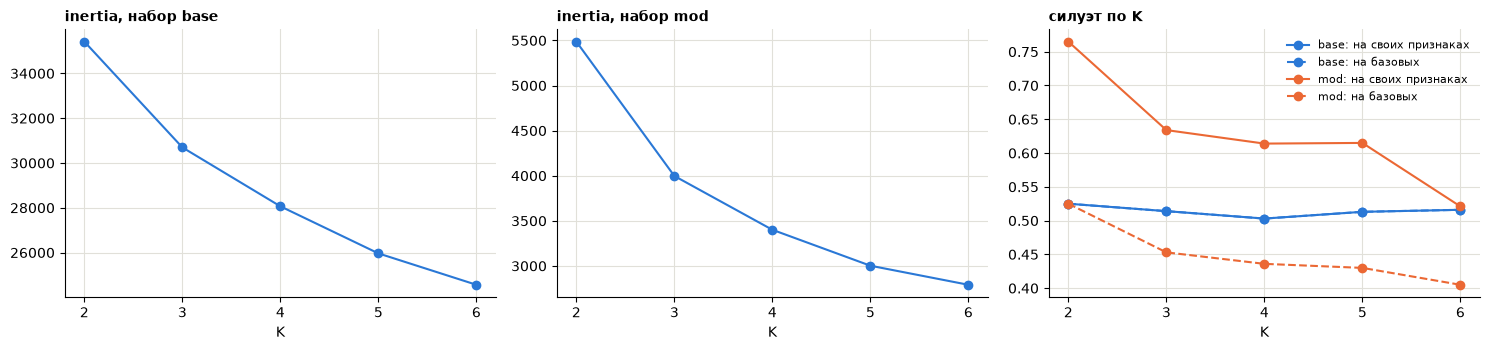

медианы исходных признаков, набор mod, K=2:


,"кластер 0, n=2749","кластер 1, n=2251"
tBodyAcc-mean()-X,0.277,0.276
tBodyAcc-mean()-Y,-0.017,-0.019
tBodyAcc-mean()-Z,-0.108,-0.111
tBodyAcc-std()-X,-0.991,-0.230
tBodyAcc-std()-Y,-0.975,-0.031
tBodyAcc-std()-Z,-0.977,-0.256
tBodyGyro-mean()-X,-0.028,-0.032
tBodyGyro-mean()-Y,-0.075,-0.076
tBodyGyro-mean()-Z,0.086,0.083
tBodyGyro-std()-X,-0.986,-0.461


медианы исходных признаков, набор mod, K=3:


,"кластер 0, n=2742","кластер 1, n=886","кластер 2, n=1372"
tBodyAcc-mean()-X,0.277,0.276,0.275
tBodyAcc-mean()-Y,-0.017,-0.020,-0.018
tBodyAcc-mean()-Z,-0.108,-0.112,-0.109
tBodyAcc-std()-X,-0.991,-0.081,-0.302
tBodyAcc-std()-Y,-0.975,0.134,-0.106
tBodyAcc-std()-Z,-0.977,-0.092,-0.329
tBodyGyro-mean()-X,-0.028,-0.035,-0.030
tBodyGyro-mean()-Y,-0.075,-0.075,-0.077
tBodyGyro-mean()-Z,0.086,0.080,0.085
tBodyGyro-std()-X,-0.986,-0.358,-0.524


ARI между разбиениями base K=2 и mod K=2: 0.995


In [4]:
# 3. Десять моделей k-means и выбор
from sklearn.metrics import silhouette_score

N = len(data)
sil_pos = np.random.default_rng(SEED).choice(N, size=min(1000, N), replace=False)
SIL_IDS = data.index[sil_pos]


def silhouette_or_nan(X, labels):
    """Силуэт определён при числе кластеров от 2 до n - 1."""
    n_labels = len(np.unique(labels))
    return silhouette_score(X, labels) if 2 <= n_labels <= len(labels) - 1 else np.nan


rows, MODELS = [], {}
for name, X in FEATURE_SETS.items():
    for k in range(2, 7):
        km = KMeans(n_clusters=k, random_state=SEED, n_init=20).fit(X)
        MODELS[(name, k)] = km
        sizes = np.bincount(km.labels_, minlength=k)
        rows.append({'признаки': name, 'K': k, 'inertia': round(km.inertia_, 1),
                     'размеры': sorted(sizes.tolist(), reverse=True), 'мин. размер': int(sizes.min()),
                     'силуэт на своих': round(silhouette_or_nan(X[sil_pos], km.labels_[sil_pos]), 3),
                     'силуэт на базовых': round(silhouette_or_nan(X_base[sil_pos], km.labels_[sil_pos]), 3)})
results = pd.DataFrame(rows)
display(results)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, name in zip(axes[:2], FEATURE_SETS):
    r = results[results['признаки'] == name]
    ax.plot(r['K'], r['inertia'], marker='o', color=COLORS[0])
    ax.set_title(f'inertia, набор {name}')
    ax.set_xlabel('K')
for i, name in enumerate(FEATURE_SETS):
    r = results[results['признаки'] == name]
    axes[2].plot(r['K'], r['силуэт на своих'], marker='o', color=COLORS[i], label=f'{name}: на своих признаках')
    axes[2].plot(r['K'], r['силуэт на базовых'], marker='o', linestyle='--', color=COLORS[i], label=f'{name}: на базовых')
axes[2].set_title('силуэт по K')
for ax in axes:
    ax.set_xticks(range(2, 7))
axes[2].set_xlabel('K')
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

# Медианы исходных признаков в кластерах для кандидатов
for name, k in [('mod', 2), ('mod', 3)]:
    labels = MODELS[(name, k)].labels_
    med = data.groupby(labels).median().T.round(3)
    med.columns = [f'кластер {c}, n={n}' for c, n in zip(med.columns, np.bincount(labels))]
    print(f'медианы исходных признаков, набор {name}, K={k}:')
    display(med)
print(f"ARI между разбиениями base K=2 и mod K=2: "
      f"{adjusted_rand_score(MODELS[('base', 2)].labels_, MODELS[('mod', 2)].labels_):.3f}")

CHOSEN_SET, K = 'mod', 2      # выбор обоснован в тексте ниже

**Таблица и графики.** Для базового набора силуэт на своих признаках и на базовых совпадает, так как это одно пространство; поэтому синие линии на графике наложились. Значения `inertia` двух наборов не сравниваю: у них разное число признаков.

- Базовый набор: силуэт почти не меняется с K (от 0.503 до 0.525). При K=5 и K=6 появляются кластеры из 38, 28 и 18 окон: это отдельные редкие окна, а не режимы.
- Изменённый набор: силуэт на своих признаках максимален при K=2 (0.765) и падает до 0.634 при K=3. На базовых признаках он тоже максимален при K=2 (0.525) и снижается до 0.453 при K=3 и до 0.405 при K=6. Минимальный размер кластера не меньше 200.
- Явного излома `inertia` нет ни в одном наборе. У изменённого набора самое большое падение между K=2 и K=3 (с 5487.3 до 3997.4), но силуэт при этом тоже падает.

**Медианы.** Для изменённого набора при K=2 кластер 0 (n=2749) - окна покоя: медианы всех `std()` от -0.991 до -0.975. Кластер 1 (n=2251) - окна движения: `tBodyAcc-std()-X` -0.230 против -0.991, `tBodyGyro-std()-X` -0.461 против -0.986. Медианы `mean()` в двух кластерах почти равны (0.277 и 0.276 у `tBodyAcc-mean()-X`): средние кластеры не разделяют. При K=3 движение делится на 1372 и 886 окон, и у второго выше медианы всех шести `std()` (например, `tBodyAcc-std()-Y` 0.134 против -0.106). Это похоже на разрез непрерывной шкалы интенсивности, а не на отдельный режим, и силуэт на базовых признаках при этом падает с 0.525 до 0.453.

**Выбор: изменённый набор, K=2.** Разбиения base и mod при K=2 почти совпадают (ARI 0.995) и имеют одинаковый силуэт на базовых признаках 0.525. Беру изменённый набор: он даёт то же разбиение по 6 признакам вместо 12, медианы `mean()` по кластерам не различаются и только добавляют шум в расстояния, а силуэт 0.765 в своём пространстве показывает хорошо отделённые группы. Гипотеза 1 подтверждается для двух групп, покоя и движения; деление движения по интенсивности убедительным не выглядит. Гипотеза 2 подтверждается частично: силуэт на своих признаках вырос с 0.525 до 0.765, но разбиение при K=2 почти не изменилось, а при K от 3 изменённый набор даёт меньший силуэт на базовых признаках.

## 4. PCA и потеря информации · 20 баллов

Работайте с **базовыми стандартизованными признаками** из задания 1.

1. Реализуйте PCA через NumPy SVD: центрирование, направления, координаты и восстановление данных. Найдите минимальное число компонент q, сохраняющее 90% дисперсии. Покажите накопленную долю дисперсии и ошибку восстановления; сверьте восстановление со sklearn PCA при том же q.
2. При K из задания 3, `random_state=42` и `n_init=20` сравните k-means на всех базовых признаках и на q компонентах. Посчитайте ARI между разбиениями и оба силуэта на базовых стандартизованных признаках.
3. На одних координатах первых двух компонент покажите оба разбиения рядом. Подпишите, какую долю дисперсии сохраняют эти две компоненты.

Объясните, что изменилось после сжатия. Учитывайте, что направления PCA могут отличаться знаком, а номера кластеров — переставляться. ARI сравнивает разбиения независимо от номеров кластеров. Сохранение дисперсии не гарантирует сохранения кластеров.

накопленная доля дисперсии: [0.452, 0.607, 0.713, 0.796, 0.868, 0.93, 0.953, 0.972, 0.981, 0.989, 0.996, 1.0]
q = 6: доля дисперсии 0.930, ошибка восстановления (средний квадрат на элемент) 0.0696


Сверка восстановления со sklearn при $q = 6$: $\max|\hat X - \hat X_{sklearn}| = 4.3e-14$

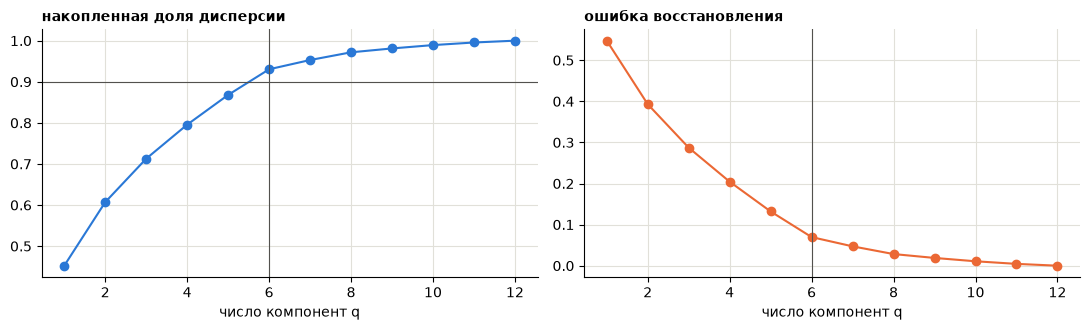

K = 2: ARI(все признаки, 6 компонент) = 1.000; силуэт на базовых: все признаки 0.525, 6 компонент 0.525


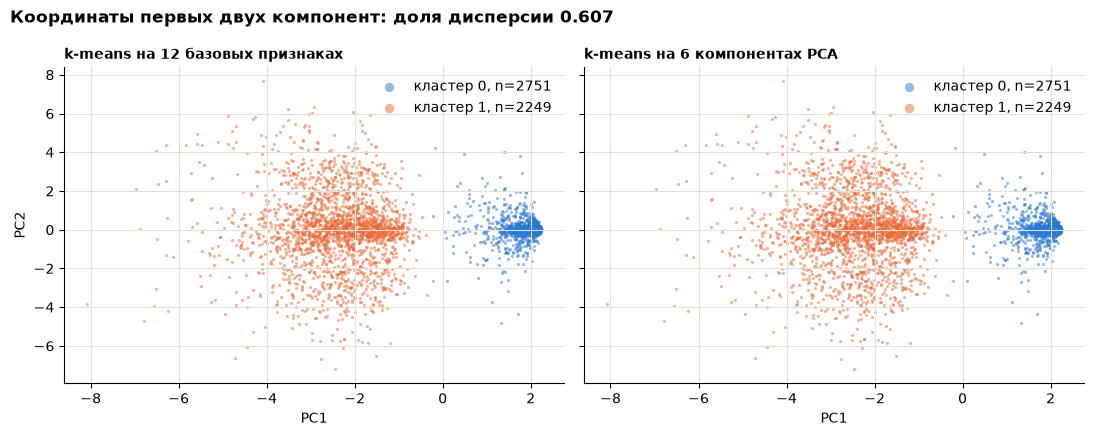

In [5]:
# 4. PCA через SVD на базовых стандартизованных признаках
from sklearn.decomposition import PCA


def pca_svd(X):
    """Центрирование и SVD: среднее, направления (строки Vt) и доли дисперсии."""
    mean = X.mean(axis=0)
    _, S, Vt = np.linalg.svd(X - mean, full_matrices=False)
    return mean, Vt, S ** 2 / (S ** 2).sum()


def pca_project(X, mean, Vt, q):
    return (X - mean) @ Vt[:q].T


def pca_restore(Z, mean, Vt, q):
    return Z @ Vt[:q] + mean


pca_mean, pca_Vt, var_ratio = pca_svd(X_base)
cum_var = np.cumsum(var_ratio)
q = int(np.argmax(cum_var >= 0.90)) + 1
rec_err = [float(np.mean((X_base - pca_restore(pca_project(X_base, pca_mean, pca_Vt, j), pca_mean, pca_Vt, j)) ** 2))
           for j in range(1, X_base.shape[1] + 1)]
sk_pca = PCA(n_components=q).fit(X_base)
X_rec = pca_restore(pca_project(X_base, pca_mean, pca_Vt, q), pca_mean, pca_Vt, q)
X_rec_sk = sk_pca.inverse_transform(sk_pca.transform(X_base))
print('накопленная доля дисперсии:', cum_var.round(3).tolist())
print(f'q = {q}: доля дисперсии {cum_var[q - 1]:.3f}, ошибка восстановления (средний квадрат на элемент) {rec_err[q - 1]:.4f}')
note(rf'Сверка восстановления со sklearn при $q = {q}$: $\max|\hat X - \hat X_{{sklearn}}| = {np.abs(X_rec - X_rec_sk).max():.1e}$')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
j = np.arange(1, X_base.shape[1] + 1)
axes[0].plot(j, cum_var, marker='o', color=COLORS[0])
axes[0].axhline(0.90, color='#52514e', linewidth=0.8)
axes[0].axvline(q, color='#52514e', linewidth=0.8)
axes[0].set_title('накопленная доля дисперсии')
axes[1].plot(j, rec_err, marker='o', color=COLORS[1])
axes[1].axvline(q, color='#52514e', linewidth=0.8)
axes[1].set_title('ошибка восстановления')
for ax in axes:
    ax.set_xlabel('число компонент q')
plt.tight_layout()
plt.show()

# k-means с выбранным K на всех базовых признаках и на q компонентах
Z_q = pca_project(X_base, pca_mean, pca_Vt, q)
labels_full = KMeans(n_clusters=K, random_state=SEED, n_init=20).fit_predict(X_base)
labels_pca = KMeans(n_clusters=K, random_state=SEED, n_init=20).fit_predict(Z_q)
print(f'K = {K}: ARI(все признаки, {q} компонент) = {adjusted_rand_score(labels_full, labels_pca):.3f}; '
      f'силуэт на базовых: все признаки {silhouette_score(X_base[sil_pos], labels_full[sil_pos]):.3f}, '
      f'{q} компонент {silhouette_score(X_base[sil_pos], labels_pca[sil_pos]):.3f}')

Z2 = pca_project(X_base, pca_mean, pca_Vt, 2)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True, sharey=True)
for ax, labels, title in [(axes[0], labels_full, 'k-means на 12 базовых признаках'),
                          (axes[1], labels_pca, f'k-means на {q} компонентах PCA')]:
    for k in range(K):
        ax.scatter(Z2[labels == k, 0], Z2[labels == k, 1], s=5, alpha=0.5, color=COLORS[k], linewidths=0,
                   label=f'кластер {k}, n={int((labels == k).sum())}')
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.legend(markerscale=3)
axes[0].set_ylabel('PC2')
fig.suptitle(f'Координаты первых двух компонент: доля дисперсии {cum_var[1]:.3f}', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

- **PCA через SVD.** Центрированная матрица $X_c = X - \mu = U S V^T$. Направления - строки $V^T$, координаты $Z = X_c V_q$, восстановление $\hat X = Z V_q^T + \mu$, доля дисперсии компоненты $s_j^2 / \sum_k s_k^2$.
- **q.** Пять компонент сохраняют 0.868 дисперсии, шесть - 0.930, поэтому $q = 6$. Ошибка восстановления при $q = 6$ - средний квадрат 0.0696 на элемент стандартизованной матрицы; она согласуется с потерянной долей дисперсии. Восстановление совпадает со sklearn до 4.3e-14, то есть различие только в округлении.
- **Сравнение разбиений.** При K=2 k-means на 12 базовых признаках и на 6 компонентах дал одно и то же разбиение: ARI 1.000, силуэт на базовых признаках 0.525 в обоих случаях.
- **График.** Первые две компоненты сохраняют 0.607 дисперсии. Кластер 0 (n=2751) - компактное облако у одного края PC1, кластер 1 (n=2249) - широкое облако с другой стороны. Разделение идёт вдоль PC1, у которой наибольшая доля дисперсии 0.452. Знак PC1 произволен: при другом знаке облака поменялись бы местами, а ARI от этого не меняется.

**Что изменилось после сжатия.** Для выбранного K разбиение не изменилось, потому что направление, по которому разделяются покой и движение, совпадает с главной компонентой, а отброшенные компоненты несут оставшуюся небольшую часть дисперсии. В общем случае сохранение 0.90 дисперсии не гарантирует сохранения кластеров: если бы кластеры различались по направлению с малой дисперсией, оно попало бы в отброшенные компоненты.

## 5. Устойчивость и описание кластеров · 15 баллов

### Повторное обучение

Зафиксируйте выбранные преобразования и K. Пять раз отберите 80% значений `group_id` случайно, без возвращения, с seed=101…105. Каждый раз берите **все строки** с выбранными значениями:

| Вариант | Что отбирать целиком |
|---|---|
| A | Пользователей: один `group_id` соответствует одному пользователю. |
| B | Строки с кандидатами радиосигнала: у каждой строки свой `group_id`. |
| C | Участников эксперимента со всеми их окнами наблюдений. |
| D | Календарные недели со всеми входящими в них днями. |

Здесь `group_id` задаёт порядок отбора данных, а не номер кластера. В C не выбирайте окна одного человека по отдельности, в D — отдельные дни: соседние наблюдения связаны.

На каждой выбранной части обучите k-means и назначьте кластеры **всем исходным объектам**. Параметры преобразований не переобучайте. Покажите пять ARI относительно исходного выбранного разбиения и оцените устойчивость. Это проверка чувствительности к составу данных; она не измеряет качество на новых объектах и не даёт доверительного интервала. Для B неизвестно, относятся ли разные строки к одному небесному источнику; недельный отбор в D также не доказывает независимость недель.

### Описание результата

Покажите размеры кластеров и медианы исходных признаков. Для двух кластеров приведите минимум два численных различия, дайте понятные названия и поясните ограничения такого описания. Для D постройте медианные почасовые кривые в числе аренд и в долях за день. Для A описывайте действия пользователей, для C учитывайте, что признаки уже нормированы источником.

In [6]:
# 5. Устойчивость: 80% участников целиком, параметры StandardScaler не переобучаются
X_chosen = FEATURE_SETS[CHOSEN_SET]
ref_labels = MODELS[(CHOSEN_SET, K)].labels_
group_values = np.sort(groups.unique())
aris = []
for seed in range(101, 106):
    picked = np.random.default_rng(seed).choice(group_values, size=round(0.8 * len(group_values)), replace=False)
    mask = groups.isin(picked).to_numpy()
    km = KMeans(n_clusters=K, random_state=SEED, n_init=20).fit(X_chosen[mask])
    aris.append(adjusted_rand_score(ref_labels, km.predict(X_chosen)))
    print(f'seed {seed}: участников {len(picked)}, окон {int(mask.sum())}, ARI с исходным разбиением {aris[-1]:.3f}')
print(f'ARI: минимум {min(aris):.3f}, медиана {np.median(aris):.3f}')

# Описание кластеров: размеры и медианы исходных признаков
med = data.groupby(ref_labels).median().T.round(3)
med.columns = [f'кластер {c}, n={n}' for c, n in zip(med.columns, np.bincount(ref_labels))]
display(med)

seed 101: участников 24, окон 3942, ARI с исходным разбиением 1.000
seed 102: участников 24, окон 3931, ARI с исходным разбиением 1.000


seed 103: участников 24, окон 4003, ARI с исходным разбиением 1.000
seed 104: участников 24, окон 3929, ARI с исходным разбиением 1.000
seed 105: участников 24, окон 3979, ARI с исходным разбиением 1.000
ARI: минимум 1.000, медиана 1.000


,"кластер 0, n=2749","кластер 1, n=2251"
tBodyAcc-mean()-X,0.277,0.276
tBodyAcc-mean()-Y,-0.017,-0.019
tBodyAcc-mean()-Z,-0.108,-0.111
tBodyAcc-std()-X,-0.991,-0.230
tBodyAcc-std()-Y,-0.975,-0.031
tBodyAcc-std()-Z,-0.977,-0.256
tBodyGyro-mean()-X,-0.028,-0.032
tBodyGyro-mean()-Y,-0.075,-0.076
tBodyGyro-mean()-Z,0.086,0.083
tBodyGyro-std()-X,-0.986,-0.461


**Устойчивость.** В каждом из пяти повторов отобраны 24 участника со всеми их окнами (от 3929 до 4003 окон). Параметры StandardScaler не переобучались; k-means обучался на отобранной части и назначал кластеры всем 5000 окнам. Все пять ARI с исходным разбиением равны 1.000 (минимум 1.000, медиана 1.000): деление на два кластера не зависит от того, какие участники попали в обучение. Это проверка чувствительности к составу участников, а не качества на новых людях: окна одного человека перекрываются наполовину, все 30 участников из одного эксперимента, а пять повторов не дают доверительного интервала.

**Описание кластеров.**

- **Покой**, кластер 0 (n=2749): медианы `tBodyAcc-std()-X` -0.991 и `tBodyGyro-std()-X` -0.986, у нижней границы шкалы. За окно телефон почти не колеблется и не вращается.
- **Движение**, кластер 1 (n=2251): `tBodyAcc-std()-X` -0.230 и `tBodyGyro-std()-X` -0.461, `tBodyAcc-std()-Y` -0.031 против -0.975 у покоя. Сильные колебания ускорения и вращения, как при ходьбе.
- Медианы `mean()` у кластеров почти равны (`tBodyAcc-mean()-X` 0.277 и 0.276), поэтому по средним кластеры не описываются.

**Ограничения.** Признаки нормированы источником в [-1, 1], поэтому -0.991 означает "у нижней границы шкалы этого признака в исходном наборе", а не физическое ускорение. Сравнивать можно только порядок значений и разницу в этой шкале. Ускорение тела дано без гравитации, поэтому положение тела не видно: кластер покоя не различает сидение, стояние и лёжа. Названия - гипотезы по признакам, а не проверенные классы; медиана не описывает разброс внутри кластера.

## 6. DBSCAN и необычные объекты · 10 баллов

Исследуйте DBSCAN на базовых стандартизованных признаках при `min_samples=10`. Покажите распределение расстояний до десятого соседа, включая саму точку. Возьмите три eps: квантили 0,50; 0,75; 0,90 этих расстояний.

Для каждого eps укажите число и размеры кластеров без шума, долю шума и долю объектов, попавших в кластеры. Если считаете силуэт, используйте только нешумовые объекты из подвыборки задания 3 и укажите их число. При недопустимом числе кластеров объясните, почему метрика не определена. Не сравнивайте эту оценку напрямую с k-means на всех объектах.

Для одного eps выберите случайно 5 шумовых и 5 нешумовых объектов; при нехватке возьмите все доступные. Покажите ID и признаки. Опишите, какие дополнительные данные нужны эксперту и что он должен проверить или отметить в этих примерах. Шум DBSCAN сам по себе не доказывает ошибку или особую природу объекта; просмотр 10 примеров не оценивает точность детектора.

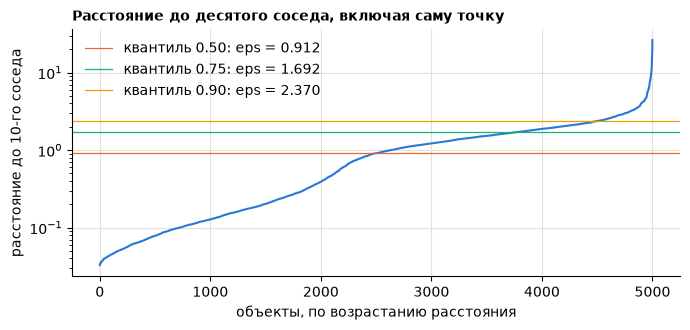

eps = 0.912 (квантиль 0.50): кластеров 3, размеры [2431, 305, 29], доля шума 0.447, доля в кластерах 0.553; силуэт 0.768 на 564 нешумовых объектах подвыборки
    доля шума внутри кластеров k-means: {0: 0.116, 1: 0.852}


eps = 1.692 (квантиль 0.75): кластеров 2, размеры [4164, 7], доля шума 0.166, доля в кластерах 0.834; силуэт 0.421 на 828 нешумовых объектах подвыборки
    доля шума внутри кластеров k-means: {0: 0.054, 1: 0.302}


eps = 2.370 (квантиль 0.90): кластеров 1, размеры [4748], доля шума 0.050, доля в кластерах 0.950; силуэт не определён: в подвыборке 1 кластер(ов) без шума
    доля шума внутри кластеров k-means: {0: 0.029, 1: 0.076}


,DBSCAN,k-means,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyGyro-mean()-X,tBodyGyro-mean()-Y,tBodyGyro-mean()-Z,tBodyGyro-std()-X,tBodyGyro-std()-Y,tBodyGyro-std()-Z
object_id,,,,,,,,,,,,,,
train_4873,шум,1,0.234,-0.114,-0.094,0.027,0.105,0.283,0.272,-0.145,-0.084,-0.657,-0.248,0.024
train_238,шум,1,-0.066,0.079,-1.000,-0.684,-0.539,-0.085,0.072,0.138,0.453,-0.207,-0.702,-0.420
train_3937,шум,1,0.618,-0.008,-0.066,0.787,0.419,0.389,-0.639,0.118,0.247,0.295,0.596,-0.045
test_2413,шум,0,0.381,0.050,0.069,-0.836,-0.584,-0.749,-0.000,0.035,-0.242,-0.775,-0.597,-0.573
train_2378,шум,1,0.200,-0.039,-0.141,-0.378,0.273,0.573,-0.061,0.136,0.265,-0.416,0.441,0.371
train_760,кластер,0,0.278,-0.017,-0.103,-0.987,-0.989,-0.990,-0.033,-0.075,0.063,-0.991,-0.988,-0.986
test_1855,кластер,0,0.280,-0.007,-0.100,-0.997,-0.963,-0.962,-0.035,-0.067,0.084,-0.974,-0.981,-0.990
train_3218,кластер,1,0.311,-0.014,-0.098,-0.415,-0.132,-0.069,0.075,0.009,-0.036,-0.466,-0.433,-0.238
train_5377,кластер,0,0.270,0.023,-0.175,-0.980,-0.799,-0.799,0.025,-0.072,0.102,-0.945,-0.964,-0.978


In [7]:
# 6. DBSCAN на базовых стандартизованных признаках, min_samples=10
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 10
dist10 = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_base).kneighbors(X_base)[0][:, -1]   # десятый сосед, считая саму точку
EPS = {qq: float(np.quantile(dist10, qq)) for qq in (0.50, 0.75, 0.90)}

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.sort(dist10), color=COLORS[0])
for i, (qq, eps) in enumerate(EPS.items()):
    ax.axhline(eps, color=COLORS[i + 1], linewidth=0.9, label=f'квантиль {qq:.2f}: eps = {eps:.3f}')
ax.set_xlabel('объекты, по возрастанию расстояния')
ax.set_ylabel('расстояние до 10-го соседа')
ax.set_yscale('log')
ax.set_title('Расстояние до десятого соседа, включая саму точку')
ax.legend()
plt.tight_layout()
plt.show()

DB_LABELS = {}
for qq, eps in EPS.items():
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_base)
    DB_LABELS[qq] = labels
    sizes = sorted(np.bincount(labels[labels >= 0]).tolist(), reverse=True) if (labels >= 0).any() else []
    ok = labels[sil_pos] >= 0
    n_clusters_sub = len(np.unique(labels[sil_pos][ok]))
    if 2 <= n_clusters_sub <= ok.sum() - 1:
        sil = f'{silhouette_score(X_base[sil_pos][ok], labels[sil_pos][ok]):.3f} на {int(ok.sum())} нешумовых объектах подвыборки'
    else:
        sil = f'не определён: в подвыборке {n_clusters_sub} кластер(ов) без шума'
    print(f'eps = {eps:.3f} (квантиль {qq:.2f}): кластеров {len(sizes)}, размеры {sizes}, '
          f'доля шума {(labels == -1).mean():.3f}, доля в кластерах {(labels >= 0).mean():.3f}; силуэт {sil}')
    print('    доля шума внутри кластеров k-means:',
          {k: round(float((labels[ref_labels == k] == -1).mean()), 3) for k in range(K)})

# Примеры для эксперта: 5 шумовых и 5 нешумовых объектов при eps для квантиля 0.90
EXAMPLE_Q = 0.90
labels = DB_LABELS[EXAMPLE_Q]
rng = np.random.default_rng(SEED)
noise_ids = rng.choice(data.index[labels == -1], size=min(5, int((labels == -1).sum())), replace=False)
core_ids = rng.choice(data.index[labels >= 0], size=min(5, int((labels >= 0).sum())), replace=False)
examples = data.loc[list(noise_ids) + list(core_ids)].round(3)
examples.insert(0, 'DBSCAN', ['шум'] * len(noise_ids) + ['кластер'] * len(core_ids))
examples.insert(1, 'k-means', ref_labels[data.index.get_indexer(examples.index)])
display(examples)

**Расстояние до десятого соседа** (с самой точкой) показано в логарифмической шкале: у большой части окон соседи очень близко, дальше расстояние плавно растёт, у последних окон резкий хвост. Плотность сильно различается: окна покоя лежат плотно, окна движения разрежены.

- eps 0.912 (квантиль 0.50): 3 кластера [2431, 305, 29], доля шума 0.447, в кластерах 0.553, силуэт 0.768 на 564 нешумовых объектах подвыборки. Шумом стали 0.852 окон кластера движения k-means и только 0.116 окон покоя: при малом eps DBSCAN находит только плотные окна покоя.
- eps 1.692 (квантиль 0.75): 2 кластера [4164, 7], шум 0.166, в кластерах 0.834, силуэт 0.421 на 828 нешумовых объектах подвыборки. Покой и большая часть движения слились в один кластер.
- eps 2.370 (квантиль 0.90): 1 кластер из 4748 окон, шум 0.050, в кластерах 0.950. Силуэт не определён: в подвыборке без шума остался один кластер, а силуэту нужно хотя бы два.
- С одним eps DBSCAN не выделяет одновременно плотный покой и разреженное движение. Силуэт DBSCAN посчитан только по нешумовым объектам и с k-means не сравнивается.

**Примеры** взяты при eps 2.370 (квантиль 0.90): там шум - только 0.050 окон, самые необычные. Среди шумовых `train_238` с `tBodyAcc-mean()-Z` -1.000 на границе шкалы, `train_3937` с `tBodyAcc-std()-X` 0.787 и `tBodyGyro-mean()-X` -0.639 (очень интенсивное движение с вращением), `test_2413` с умеренным `tBodyAcc-std()-X` -0.836 (k-means отнёс его к покою, возможно, это переход между позами). Нешумовые примеры типичные: четыре окна покоя с `std()` около -0.99 и одно окно движения `train_3218`.

**Что нужно эксперту.** Исходные сигналы окна (трёхосевое ускорение с гравитацией и гироскоп), соседние по времени окна того же участника, номер участника и сессии, протокол эксперимента с заданием в этот момент и видеозапись, если она есть. Для каждого примера проверить и отметить: переход между режимами (встал, сел, лёг), артефакт датчика или смещение телефона на поясе, значения на границе шкалы нормировки, обычное интенсивное движение или неясно. Шум DBSCAN сам по себе не означает ошибку, а 10 примеров не оценивают точность детектора.

## 7. Итог и дополнительная проверка · 5 баллов

До просмотра отложенных метаданных зафиксируйте в ноутбуке выбранные признаки, преобразования и их параметры, K, seed, `n_init`, eps и ID подвыборки. Покажите назначения кластеров по `object_id`.

После этого можно выполнить дополнительную проверку: для B/C — ARI и таблицу сопоставления с известными классами, для D — распределение типов дней по кластерам. Для A внешних классов нет. Проверка необязательна; после неё модель не меняйте. Высокое совпадение с классами дополнительных баллов не даёт.

Напишите вывод на 250–400 слов: вопрос, выбранное решение, ключевые числа, устойчивость, эффект PCA, трактовка шума, ограничения и следующая проверка. Ответьте на индивидуальный вопрос из Stepik. Укажите, что потребуется для работы с новыми объектами или будущими периодами.

In [8]:
# 7. Фиксация выбора до просмотра отложенных метаданных
import hashlib
import platform

import matplotlib
import scipy
import sklearn

chosen_scaler = scaler_mod if CHOSEN_SET == 'mod' else scaler_base
FIXED = {
    'признаки': STD_COLS if CHOSEN_SET == 'mod' else list(data.columns),
    'преобразование': 'StandardScaler, обучен на всех 5000 окнах',
    'StandardScaler.mean_': chosen_scaler.mean_.round(4).tolist(),
    'StandardScaler.scale_': chosen_scaler.scale_.round(4).tolist(),
    'K': K, 'random_state': SEED, 'n_init': 20,
    'DBSCAN': {'min_samples': MIN_SAMPLES, 'eps': {str(qq): round(eps, 4) for qq, eps in EPS.items()}},
    'подвыборка для силуэта': {'размер': len(SIL_IDS), 'seed': SEED, 'первые 10 ID': SIL_IDS[:10].tolist(),
                               'sha256 ID': hashlib.sha256(','.join(SIL_IDS).encode()).hexdigest()},
}
for key, value in FIXED.items():
    print(f'{key}: {value}')
ASSIGNMENT = pd.Series(ref_labels, index=data.index, name='cluster')
print('назначения кластеров по object_id, первые 10:', ASSIGNMENT.head(10).to_dict())
print('размеры кластеров:', ASSIGNMENT.value_counts().sort_index().to_dict())

признаки: ['tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyGyro-std()-X', 'tBodyGyro-std()-Y', 'tBodyGyro-std()-Z']
преобразование: StandardScaler, обучен на всех 5000 окнах
StandardScaler.mean_: [-0.614, -0.5179, -0.6163, -0.7258, -0.6854, -0.66]
StandardScaler.scale_: [0.4359, 0.4971, 0.4046, 0.2971, 0.358, 0.3682]
K: 2
random_state: 42
n_init: 20
DBSCAN: {'min_samples': 10, 'eps': {'0.5': 0.9123, '0.75': 1.6917, '0.9': 2.3703}}
подвыборка для силуэта: {'размер': 1000, 'seed': 42, 'первые 10 ID': ['train_4346', 'train_4405', 'train_2209', 'train_3654', 'train_1585', 'test_635', 'train_58', 'test_2028', 'test_2878', 'train_1633'], 'sha256 ID': '0bee791386d2d8b1f81d1c7a4898ea17e0bdaa110e7e37848de49f3e08449306'}
назначения кластеров по object_id, первые 10: {'test_1': 0, 'test_10': 0, 'test_1000': 1, 'test_1002': 1, 'test_1003': 1, 'test_1009': 1, 'test_1011': 1, 'test_1016': 1, 'test_1017': 1, 'test_1019': 1}
размеры кластеров: {0: 2749, 1: 2251}


In [9]:
# 7. Дополнительная проверка по известным классам: модель после неё не меняется
ACTIVITY = {1: 'ходьба', 2: 'подъём по лестнице', 3: 'спуск', 4: 'сидение', 5: 'стояние', 6: 'лёжа'}
with ZipFile(DATA_FILE) as archive:
    audit = pd.read_csv(archive.open(member('metadata')), usecols=['object_id', 'audit_label'], dtype={'object_id': str})
audit = audit.set_index('object_id').loc[data.index, 'audit_label'].map(ACTIVITY)
print(f'ARI с известными классами: {adjusted_rand_score(audit, ASSIGNMENT):.3f}')
display(pd.crosstab(audit, ASSIGNMENT, margins=True, margins_name='всего'))

print(f'Python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}, '
      f'scikit-learn {sklearn.__version__}, scipy {scipy.__version__}, matplotlib {matplotlib.__version__}')
print(f'устройство: {platform.machine()}, {platform.platform()}; время полного запуска {time.perf_counter() - T_START:.1f} с')

ARI с известными классами: 0.329


cluster,0,1,всего
audit_label,,,
лёжа,972,9,981
подъём по лестнице,0,706,706
сидение,870,5,875
спуск,0,682,682
стояние,907,1,908
ходьба,0,848,848
всего,2749,2251,5000


Python 3.12.14, numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, scipy 1.18.1, matplotlib 3.11.2
устройство: arm64, macOS-26.6.2-arm64-arm-64bit; время полного запуска 4.2 с


**Дополнительная проверка** выполнена после фиксации выбора, модель после неё не менялась. ARI с шестью известными классами 0.329. Кластер движения содержит все окна ходьбы (848), подъёма (706) и спуска (682), кластер покоя - лёжа 972, сидение 870, стояние 907. В чужой кластер попали только 9 окон лёжа, 5 сидения и 1 стояния, т.е. низкой активности. ARI невысок, потому что два кластера сравниваются с шестью классами: разбиение совпадает с делением на покой и движение, а не с отдельными активностями.

**Индивидуальный вопрос.** скип.

**Окружение.** MacBook на M3 Pro, библиотеки с принта выше.

### Вывод

Вопрос: какие режимы движения можно выделить без меток по 12 признакам окон акселерометра и гироскопа и насколько устойчиво это деление.

Решение: k-means с K=2 на 6 признаках `std()` после StandardScaler, `random_state=42`, `n_init=20`. Кластеры: покой (2749 окон) и движение (2251 окно). В покое медианы `std()` у нижней границы шкалы (`tBodyAcc-std()-X` -0.991), в движении заметно выше (-0.230). Силуэт 0.765 на своих признаках и 0.525 на базовых. При K от 3 силуэт на базовых признаках падает (0.453 при K=3), а новые кластеры делят движение по интенсивности или выделяют группы из десятков окон. Разбиение почти не зависит от набора признаков: ARI между base и mod при K=2 равен 0.995.

Устойчивость: при пяти отборах 24 из 30 участников все ARI с исходным разбиением равны 1.000. Но это только чувствительность к составу участников одного эксперимента.

PCA: 6 компонент сохраняют 0.930 дисперсии, k-means на них дал то же разбиение (ARI 1.000, силуэт 0.525), потому что кластеры разделяются вдоль первой компоненты. В общем случае сохранение дисперсии этого не гарантирует.

Шум DBSCAN: плотность покоя и движения сильно различается, поэтому при eps квантиля 0.50 шумом становятся 0.852 окон движения, а при квантиле 0.90 всё сливается в один кластер с шумом 0.050. Шумовые окна - кандидаты на проверку экспертом (переходы между позами, значения на границе шкалы), а не доказанные ошибки.

Ограничения: признаки нормированы источником и не дают физических единиц; без гравитационной составляющей покой не делится на сидение, стояние и лёжа; окна перекрываются; все данные из одного эксперимента. Проверка по известным классам подтвердила только деление на покой и движение.

Следующая проверка: добавить признаки ориентации (гравитацию, углы наклона) и проверить, делится ли покой на позы, а также проверить разбиение на участниках, которых не было в данных.

Новые объекты и будущие периоды: нужны те же 12 признаков с той же нормировкой источника, сохранённые параметры StandardScaler (выведены выше) и центры k-means. Новые окна только назначаются ближайшему центру без переобучения. Для другого телефона, другого крепления или другой группы людей нужно заново сравнить распределения признаков и долю окон у границы между кластерами, а при заметном сдвиге переобучить модель и повторить проверку устойчивости.

## Оценивание

| Блок | Баллы | За что начисляются |
|---|---:|---|
| Данные и подготовка признаков | 15 | Постановка и гипотезы 5; аудит 5; два набора признаков и их обоснование 5 |
| Реализация k-means | 15 | Назначение 4; центры и пустые кластеры 4; целевая функция и сверка 7 |
| Сравнение и выбор кластеров | 20 | Таблица 10 моделей 8; сопоставимые оценки 6; обоснованный выбор 6 |
| PCA | 20 | SVD и проверка восстановления 8; дисперсия и q 5; сравнение разбиений и графики 7 |
| Устойчивость и описание | 15 | Пять повторов с правильным отбором и интерпретацией 8; описание кластеров 7 |
| DBSCAN и проверка примеров | 10 | Три запуска, доля нешумовых объектов и корректные метрики 6; план проверки 4 |
| Воспроизводимость и итог | 5 | Полный запуск, фиксация выбора и обоснованный вывод |
| **Всего** | **100** | |

Баллы начисляются за выполненные пункты. Если известные классы использованы для подбора модели, соответствующие пункты выбора и выводов не засчитываются; остальные части оцениваются отдельно. Низкая метрика или обоснованный вывод об отсутствии пригодных кластеров сами по себе не снижают оценку.

## Что сдавать

Один выполненный ноутбук с кодом, таблицами, графиками и выводами. Укажите версии Python и библиотек, устройство и время полного запуска. Перед сдачей перезапустите среду и выполните ячейки по порядку.

Дополнительный отчёт, презентация, архив исходных данных и отдельные таблицы не нужны. Достаточно CPU и библиотек NumPy, pandas, matplotlib, scikit-learn и SciPy.

# Справочник данных

В `*_features.csv` находятся признаки и `object_id`. В `*_metadata.csv` — `group_id` для задания 5 и отложенные сведения для задания 7. ID не используйте как признаки.

## A · Яндекс Музыка / Yambda

Одна строка — пользователь. Выданы 5000 пользователей с минимум 20 событиями постановки лайка из [Yambda-50M](https://huggingface.co/datasets/yandex/yambda). Пользователи без лайков и с редкими лайками в эту выборку не входят.

| Признак | Что означает |
|---|---|
| `like_count` | Число событий постановки лайка |
| `unique_tracks` | Число разных треков в этих событиях |
| `active_days` | Число суток, в которые поставлен хотя бы один лайк |
| `span_days` | Время между первым и последним лайком, в сутках |
| `organic_share` | Доля лайков при самостоятельном выборе трека, без перехода из рекомендаций; от 0 до 1 |
| `peak_day_share` | Максимальная доля лайков пользователя, поставленная за одни сутки |
| `likes_per_active_day` | Число лайков, делённое на `active_days` |
| `median_gap_hours` | Медиана времени между последовательными лайками, в часах; нули допустимы |

Сутки отсчитываются от условного начала набора. Реальные даты, часовой пояс, названия и жанры треков не раскрыты. Считаются события лайков без вычитания отмен: это не размер текущего избранного и не число прослушиваний. `organic_share` описывает канал действия, но не доказывает влияние рекомендаций на поведение. Правильных внешних классов для этого варианта нет. `group_id` — ID пользователя.

## B · Радиосигналы HTRU2

Одна строка — кандидат радиосигнала. Выданы 5000 строк из [HTRU2](https://archive.ics.uci.edu/dataset/372/htru2).

- `profile_*` описывают форму усреднённого импульса.
- `dm_*` описывают кривую отношения сигнал/шум при разных настройках обработки сигнала.
- Для каждого описания даны среднее (`mean`), стандартное отклонение (`std`), асимметрия (`skewness`) и эксцесс (`excess_kurtosis`). Среднее и std — в шкалах исходного сигнала, асимметрия и эксцесс безразмерны.

`group_id` совпадает с ID строки: неизвестно, могут ли разные строки относиться к одному небесному источнику. Отложенная метка `audit_label`: 1 — подтверждённый пульсар, 0 — отрицательный пример. Полных наблюдений для экспертной проверки в таблице нет.

## C · Датчики смартфона / UCI HAR

Одна строка — окно измерений длительностью 2,56 секунды. Выданы 5000 окон из [UCI HAR](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones).

12 признаков — средние (`mean()`) и стандартные отклонения (`std()`) по осям X/Y/Z:

- `tBodyAcc-*` — характеристики ускорения тела;
- `tBodyGyro-*` — характеристики угловой скорости.

Источник уже нормировал значения примерно в диапазон [-1; 1]. Их нельзя читать как физические ускорения или угловые скорости. Окна одного участника перекрываются на 50%, поэтому при повторном отборе сохраняйте все его окна вместе. `group_id` — участник эксперимента.

Отложенная метка `audit_label`: 1 — ходьба, 2 — подъём по лестнице, 3 — спуск, 4 — сидение, 5 — стояние, 6 — положение лёжа. Эти классы не задают число кластеров. Официальные train/test объединены для описания выданного набора; качество на новых людях здесь не проверяется.

## D · Велопрокат Сеула

Одна строка — день работы проката. Выданы 352 дня из [Seoul Bike Sharing Demand](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand).

`hour_00`…`hour_23` — число аренд за каждый час этого дня. Оставлены полные дни, когда прокат работал все 24 часа; 13 дней с часами неработающего сервиса исключены. `group_id` — календарная неделя.

В исходных числах сравнивается объём спроса. После деления на сумму за день сравнивается распределение аренд по часам; последующая стандартизация также меняет вес каждого часа. Сезон, праздничность и тип дня находятся в отложенных метаданных. Они помогают описать кластеры, но не доказывают причины изменения спроса.

## Источники и подготовка

Yambda: Copyright 2025 YANDEX LLC, Apache 2.0; [статья авторов](https://arxiv.org/abs/2505.22238). Источники трёх остальных наборов — UCI, CC BY 4.0. Данные подготовлены преподавателем: выбраны строки и признаки, для A рассчитаны показатели по пользователям, для D почасовые записи объединены по дням. Ссылки на источники, точные правила отбора и контрольные суммы сохранены в `datasets.json` внутри архива; лицензия Yambda также включена в архив.